In [2]:
import torch
from torchvision.models import swin_t, Swin_T_Weights

In [3]:
device = 'cpu'
if torch.cuda.is_available():
    device = 'cuda'

In [4]:
weights = Swin_T_Weights.DEFAULT
swin = swin_t(weights=weights)

In [ ]:
import torch
from torchvision.models import swin_t, Swin_T_Weights


swin = swin_t(weights=Swin_T_Weights.DEFAULT)


x = torch.randn(2, 3, 224, 224)


layer_outputs = []

for layer in swin.features:
    x = layer(x)
    layer_outputs.append(x)


for i, output in enumerate(layer_outputs):
    print(f"Layer {i}: {output.shape}")

Layer 0: torch.Size([2, 56, 56, 96])
Layer 1: torch.Size([2, 56, 56, 96])
Layer 2: torch.Size([2, 28, 28, 192])
Layer 3: torch.Size([2, 28, 28, 192])
Layer 4: torch.Size([2, 14, 14, 384])
Layer 5: torch.Size([2, 14, 14, 384])
Layer 6: torch.Size([2, 7, 7, 768])
Layer 7: torch.Size([2, 7, 7, 768])


In [6]:
F1 = layer_outputs[1]
F2 = layer_outputs[3]
F3 = layer_outputs[5]
F4 = layer_outputs[7]

In [7]:
import torch.nn as nn

In [8]:
import torch.nn as nn
import torch.nn.functional as F

class Decoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.proj4=nn.Conv2d(768,256,1)
        self.proj3=nn.Conv2d(384,256,1)
        self.proj2=nn.Conv2d(192,256,1)
        self.proj1=nn.Conv2d(96,256,1)
        self.damage_head=nn.Conv2d(256,9,1)
        self.structure_head=nn.Conv2d(256,1,1)

    def forward(self,F1,F2,F3,F4):

        F1=F1.permute(0,3,1,2)
        F2=F2.permute(0,3,1,2)
        F3=F3.permute(0,3,1,2)
        F4=F4.permute(0,3,1,2)

        F4=self.proj4(F4)
        F3=self.proj3(F3)
        F2=self.proj2(F2)
        F1=self.proj1(F1)

        F4=F.interpolate(F4,size=(14,14),mode="bilinear",align_corners=False)
        F3=F3+F4

        F3=F.interpolate(F3,size=(28,28),mode="bilinear",align_corners=False)
        F2=F2+F3

        F2=F.interpolate(F2,size=(56,56),mode="bilinear",align_corners=False)
        F1=F1+F2

        X=F.interpolate(F1,size=(224,224),mode="bilinear",align_corners=False)

        Damage=self.damage_head(X)
        Structure=self.structure_head(X)

        return Damage,Structure

In [ ]:
class Model(nn.Module):
    def __init__(self,swin):
        super().__init__()
        self.swin=swin
        self.decoder=Decoder()

    def forward(self,x):
        features=[]
        for layer in self.swin.features:
            x=layer(x)
            features.append(x)

        F1=features[1]
        F2=features[3]
        F3=features[5]
        F4=features[7]

        Damage,Structure=self.decoder(F1,F2,F3,F4)

        return Damage,Structure

In [10]:
import os
import json
import torch
import numpy as np
from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms
from PIL import ImageDraw

In [11]:
class StructuralDataset(Dataset):
    def __init__(self,image_dir,label_dir,image_size=224):
        self.image_dir=image_dir
        self.label_dir=label_dir
        self.image_size=image_size

        self.images=[
            f for f in os.listdir(image_dir)
            if f.endswith((".jpg",".jpeg",".png"))
        ]

        self.transform=transforms.Compose([
            transforms.Resize((image_size,image_size)),
            transforms.ToTensor()
        ])

        self.class_map={
            "background":0,
            "Concrete crushing":1,
            "Delamination":2,
            "Microcrack":3,
            "Minor spalling":4,
            "Moderate spalling":5,
            "Rebar corrosion":6,
            "Structural crack":7,
            "Structural deformation":8
        }

    def __len__(self):
        return len(self.images)

    def __getitem__(self,idx):
        image_name=self.images[idx]

        image_path=os.path.join(
            self.image_dir,
            image_name
        )

        label_path=os.path.join(
            self.label_dir,
            os.path.splitext(image_name)[0]+".json"
        )

        image=Image.open(image_path).convert("RGB")

        with open(label_path,"r") as f:
            data=json.load(f)

        width=data["imageWidth"]
        height=data["imageHeight"]

        mask=Image.new(
            "L",
            (width,height),
            0
        )

        draw=ImageDraw.Draw(mask)

        labels=[]

        for shape in data["shapes"]:

            label=shape["label"]
            points=shape["points"]

            polygon=[
                (int(x),int(y))
                for x,y in points
            ]

            class_id=self.class_map[label]

            draw.polygon(
                polygon,
                fill=class_id
            )

            labels.append(label)

        image=self.transform(image)

        mask=mask.resize(
            (self.image_size,self.image_size),
            Image.Resampling.NEAREST
        )

        mask=torch.tensor(
            np.array(mask),
            dtype=torch.long
        )

        return image,mask

In [12]:
dataset=StructuralDataset(
    "/storage/jothi/Sudhanshu/Reinforced concrete structure segmentation dataset/imagedata",
    "/storage/jothi/Sudhanshu/Reinforced concrete structure segmentation dataset/labeldata",
    image_size=224
)

In [13]:
print(len(dataset))

1178


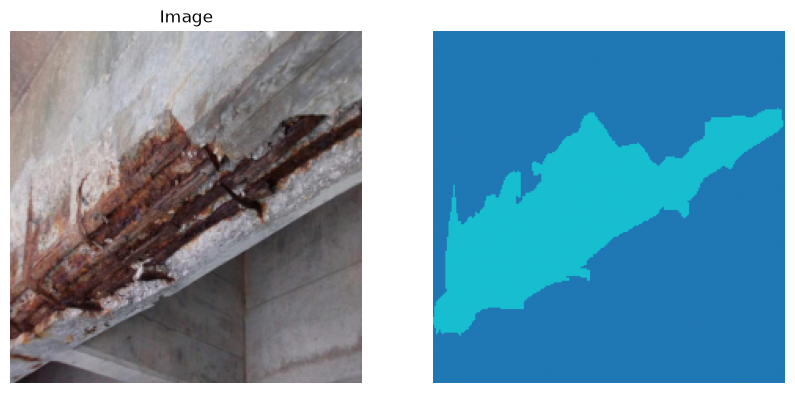

In [15]:
import matplotlib.pyplot as plt

image,mask=dataset[0]

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(image.permute(1,2,0))
plt.title("Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(mask,cmap="tab10",vmin=0,vmax=4)
plt.axis("off")

plt.show()

In [16]:
model=Model(swin)

In [17]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")

model=model.to(device)

print("Model:",next(model.parameters()).device)
print("Decoder:",next(model.decoder.parameters()).device)

Model: cuda:0
Decoder: cuda:0


In [18]:
image,mask=dataset[0]

image=image.unsqueeze(0).to(device)

model.eval()

with torch.no_grad():
    Damage,structure=model(image)

print(Damage.shape)
print(structure.shape)

torch.Size([1, 9, 224, 224])
torch.Size([1, 1, 224, 224])


In [19]:
from torch.utils.data import DataLoader,random_split

train_size=int(0.8*len(dataset))
val_size=len(dataset)-train_size

train_dataset,val_dataset=random_split(
    dataset,
    [train_size,val_size]
)

train_loader=DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0
)

val_loader=DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)

In [20]:
## Freezing swin

for param in model.swin.parameters():
    param.requires_grad=False

In [21]:
model=model.to(device)

print(device)

cuda


In [22]:
damage_criterion = nn.CrossEntropyLoss()
structure_criterion = nn.BCEWithLogitsLoss()
structure_weight = 0.5

In [23]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-5
)

In [24]:
def dice_score(pred, target, num_classes=9, eps=1e-6):

    dice = 0.0

    for cls in range(num_classes):

        pred_cls = (pred == cls)
        target_cls = (target == cls)

        intersection = (pred_cls & target_cls).sum()

        dice_cls = (
            2 * intersection + eps
        ) / (
            pred_cls.sum() + target_cls.sum() + eps
        )

        dice += dice_cls

    return dice / num_classes

In [25]:
def iou_score(pred, target, num_classes=9, eps=1e-6):

    iou = 0.0

    for cls in range(num_classes):

        pred_cls = (pred == cls)
        target_cls = (target == cls)

        intersection = (pred_cls & target_cls).sum()

        union = (
            pred_cls | target_cls
        ).sum()

        iou_cls = (
            intersection + eps
        ) / (
            union + eps
        )

        iou += iou_cls

    return iou / num_classes

def pixel_accuracy(pred, target):

    correct = (pred == target).sum()

    total = target.numel()

    return correct.float() / total

In [31]:
epochs = 110

train_losses = []
train_dice = []
train_iou = []
train_acc = []

val_losses = []
val_dice = []
val_iou = []
val_acc = []

In [32]:
## To resume traning

checkpoint = torch.load(
    "checkpoint.pth",
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

epoch = checkpoint["epoch"]
loss = checkpoint["loss"]


KeyError: 'loss'

In [33]:
for epoch in range(epochs):

    # ==================================================
    # TRAINING
    # ==================================================

    model.train()

    total_loss = 0
    total_dice = 0
    total_iou = 0
    total_acc = 0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.to(device).long()

        optimizer.zero_grad()

        # -------------------------
        # Forward
        # -------------------------

        Damage, Structure = model(images)

        # -------------------------
        # Damage loss
        # -------------------------

        damage_loss = damage_criterion(
            Damage,
            masks
        )

        # -------------------------
        # Structure target
        # -------------------------

        structure_mask = (
            masks > 0
        ).float().unsqueeze(1)

        # -------------------------
        # Structure loss
        # -------------------------

        structure_loss = structure_criterion(
            Structure,
            structure_mask
        )

        # -------------------------
        # Total loss
        # -------------------------

        loss = (
            damage_loss
            + structure_weight * structure_loss
        )

        # -------------------------
        # Backprop
        # -------------------------

        loss.backward()

        optimizer.step()

        # -------------------------
        # Prediction
        # -------------------------

        pred = torch.argmax(
            Damage,
            dim=1
        )

        # -------------------------
        # Metrics
        # -------------------------

        dice = dice_score(pred, masks)
        iou = iou_score(pred, masks)
        acc = pixel_accuracy(pred, masks)

        total_loss += loss.item()
        total_dice += dice.item()
        total_iou += iou.item()
        total_acc += acc.item()

    # -------------------------
    # Train averages
    # -------------------------

    avg_loss = total_loss / len(train_loader)
    avg_dice = total_dice / len(train_loader)
    avg_iou = total_iou / len(train_loader)
    avg_acc = total_acc / len(train_loader)

    train_losses.append(avg_loss)
    train_dice.append(avg_dice)
    train_iou.append(avg_iou)
    train_acc.append(avg_acc)


    # ==================================================
    # VALIDATION
    # ==================================================

    model.eval()

    val_total_loss = 0
    val_total_dice = 0
    val_total_iou = 0
    val_total_acc = 0

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(device)
            masks = masks.to(device).long()

            Damage, Structure = model(images)

            # -------------------------
            # Damage loss
            # -------------------------

            damage_loss = damage_criterion(
                Damage,
                masks
            )

            # -------------------------
            # Structure target
            # -------------------------

            structure_mask = (
                masks > 0
            ).float().unsqueeze(1)

            # -------------------------
            # Structure loss
            # -------------------------

            structure_loss = structure_criterion(
                Structure,
                structure_mask
            )

            # -------------------------
            # Total loss
            # -------------------------

            loss = (
                damage_loss
                + structure_weight * structure_loss
            )

            # -------------------------
            # Prediction
            # -------------------------

            pred = torch.argmax(
                Damage,
                dim=1
            )

            # -------------------------
            # Metrics
            # -------------------------

            dice = dice_score(pred, masks)
            iou = iou_score(pred, masks)
            acc = pixel_accuracy(pred, masks)

            val_total_loss += loss.item()
            val_total_dice += dice.item()
            val_total_iou += iou.item()
            val_total_acc += acc.item()

    # -------------------------
    # Validation averages
    # -------------------------

    avg_val_loss = (
        val_total_loss / len(val_loader)
    )

    avg_val_dice = (
        val_total_dice / len(val_loader)
    )

    avg_val_iou = (
        val_total_iou / len(val_loader)
    )

    avg_val_acc = (
        val_total_acc / len(val_loader)
    )

    val_losses.append(avg_val_loss)
    val_dice.append(avg_val_dice)
    val_iou.append(avg_val_iou)
    val_acc.append(avg_val_acc)


    # ==================================================
    # EPOCH RESULT
    # ==================================================

    print(
        f"Epoch [{epoch+1}/{epochs}] | "
        f"Train Loss: {avg_loss:.4f} | "
        f"Train Dice: {avg_dice:.4f} | "
        f"Train IoU: {avg_iou:.4f} | "
        f"Train Acc: {avg_acc:.4f} || "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Dice: {avg_val_dice:.4f} | "
        f"Val IoU: {avg_val_iou:.4f} | "
        f"Val Acc: {avg_val_acc:.4f}"
    )

Epoch [1/110] | Train Loss: 0.3078 | Train Dice: 0.6385 | Train IoU: 0.5918 | Train Acc: 0.9190 || Val Loss: 0.2952 | Val Dice: 0.7273 | Val IoU: 0.6839 | Val Acc: 0.9309
Epoch [2/110] | Train Loss: 0.3019 | Train Dice: 0.6414 | Train IoU: 0.5955 | Train Acc: 0.9209 || Val Loss: 0.2973 | Val Dice: 0.7099 | Val IoU: 0.6665 | Val Acc: 0.9305
Epoch [3/110] | Train Loss: 0.2970 | Train Dice: 0.6248 | Train IoU: 0.5783 | Train Acc: 0.9212 || Val Loss: 0.3003 | Val Dice: 0.6768 | Val IoU: 0.6325 | Val Acc: 0.9295
Epoch [4/110] | Train Loss: 0.2948 | Train Dice: 0.6284 | Train IoU: 0.5815 | Train Acc: 0.9212 || Val Loss: 0.3054 | Val Dice: 0.7308 | Val IoU: 0.6871 | Val Acc: 0.9276
Epoch [5/110] | Train Loss: 0.2935 | Train Dice: 0.6436 | Train IoU: 0.5988 | Train Acc: 0.9226 || Val Loss: 0.3131 | Val Dice: 0.7127 | Val IoU: 0.6691 | Val Acc: 0.9256
Epoch [6/110] | Train Loss: 0.2948 | Train Dice: 0.6448 | Train IoU: 0.5984 | Train Acc: 0.9203 || Val Loss: 0.3059 | Val Dice: 0.7186 | Val IoU:

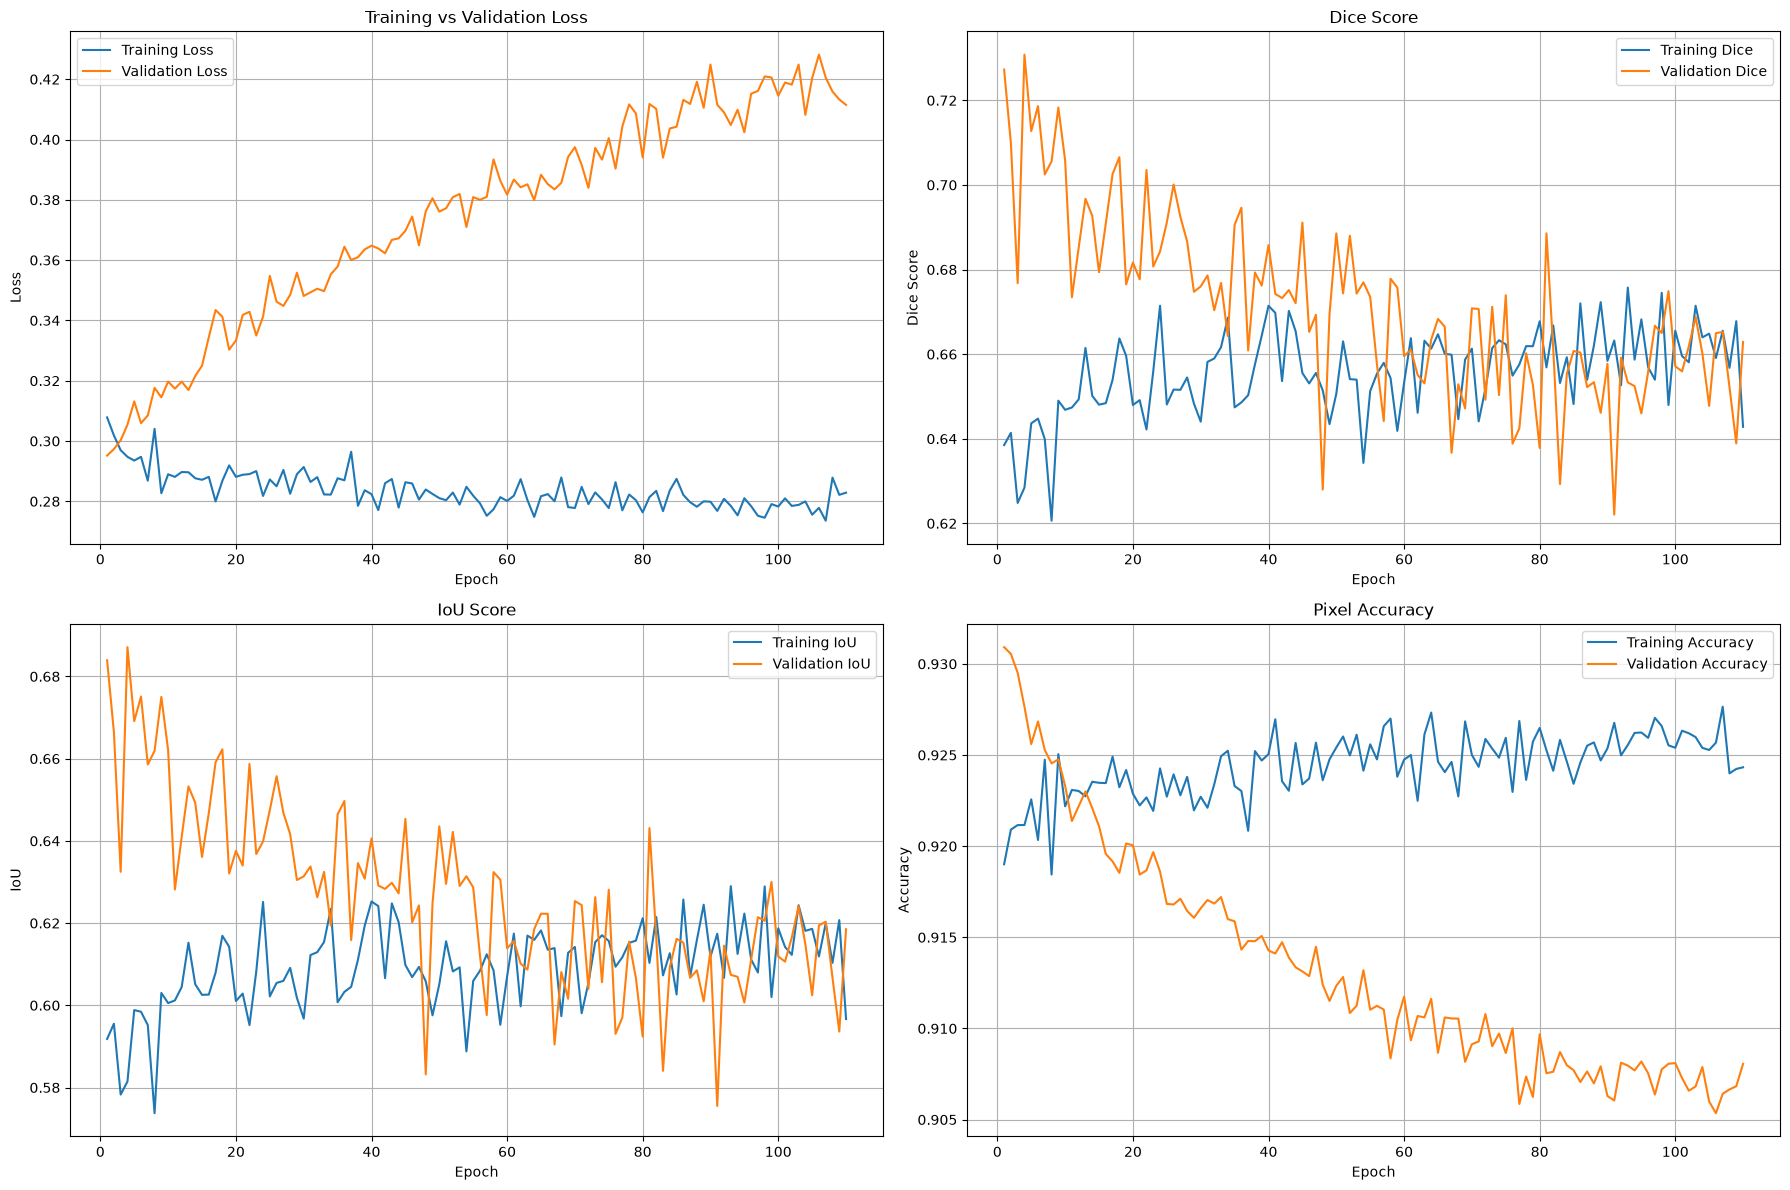

In [34]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(train_losses) + 1)

plt.figure(figsize=(18, 12))

# ---------------- LOSS ----------------
plt.subplot(2, 2, 1)

plt.plot(
    epochs_range,
    train_losses,
    label="Training Loss"
)

plt.plot(
    epochs_range,
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)


# ---------------- DICE ----------------
plt.subplot(2, 2, 2)

plt.plot(
    epochs_range,
    train_dice,
    label="Training Dice"
)

plt.plot(
    epochs_range,
    val_dice,
    label="Validation Dice"
)

plt.xlabel("Epoch")
plt.ylabel("Dice Score")
plt.title("Dice Score")
plt.legend()
plt.grid(True)


# ---------------- IoU ----------------
plt.subplot(2, 2, 3)

plt.plot(
    epochs_range,
    train_iou,
    label="Training IoU"
)

plt.plot(
    epochs_range,
    val_iou,
    label="Validation IoU"
)

plt.xlabel("Epoch")
plt.ylabel("IoU")
plt.title("IoU Score")
plt.legend()
plt.grid(True)


# ---------------- ACCURACY ----------------
plt.subplot(2, 2, 4)

plt.plot(
    epochs_range,
    train_acc,
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    val_acc,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Pixel Accuracy")
plt.legend()
plt.grid(True)


plt.tight_layout()
plt.show()

In [28]:
import torch
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.colors import ListedColormap, BoundaryNorm

damage_classes = [
    "Background",
    "Concrete crushing",
    "Delamination",
    "Microcrack",
    "Minor spalling",
    "Moderate spalling",
    "Rebar corrosion",
    "Structural crack",
    "Structural deformation"
]

cmap = ListedColormap([
    "black",
    "red",
    "orange",
    "yellow",
    "lime",
    "cyan",
    "blue",
    "magenta",
    "purple"
])

norm = BoundaryNorm(
    range(len(damage_classes) + 1),
    cmap.N
)


def plot_prediction(
    model,
    image_path,
    dataset,
    device,
    alpha=0.45
):

    image = Image.open(image_path).convert("RGB")

    original_image = image.resize((224, 224))

    image_tensor = dataset.transform(image)
    image_tensor = image_tensor.unsqueeze(0).to(device)

    model.eval()

    with torch.no_grad():
        Damage, Structure = model(image_tensor)

    damage_pred = torch.argmax(
        Damage,
        dim=1
    )

    damage_pred = damage_pred[0].cpu().numpy()

    structure_prob = torch.sigmoid(Structure)

    structure_pred = (
        structure_prob > 0.5
    ).float()

    structure_pred = (
        structure_pred[0, 0]
        .cpu()
        .numpy()
    )

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(20, 6)
    )

    axes[0].imshow(original_image)

    axes[0].set_title(
        "Input Image",
        fontsize=14
    )

    axes[0].axis("off")

    axes[1].imshow(original_image)

    damage_overlay = axes[1].imshow(
        damage_pred,
        cmap=cmap,
        norm=norm,
        alpha=alpha
    )

    axes[1].set_title(
        "Predicted Damage Overlay",
        fontsize=14
    )

    axes[1].axis("off")

    axes[2].imshow(original_image)

    axes[2].imshow(
        structure_pred,
        cmap="gray",
        alpha=0.5
    )

    axes[2].set_title(
        "Predicted Structure",
        fontsize=14
    )

    axes[2].axis("off")

    cbar = fig.colorbar(
        damage_overlay,
        ax=axes[1],
        ticks=range(len(damage_classes)),
        fraction=0.046,
        pad=0.04
    )

    cbar.ax.set_yticklabels(
        damage_classes
    )

    cbar.set_label(
        "Damage Type"
    )

    plt.tight_layout()
    plt.show()

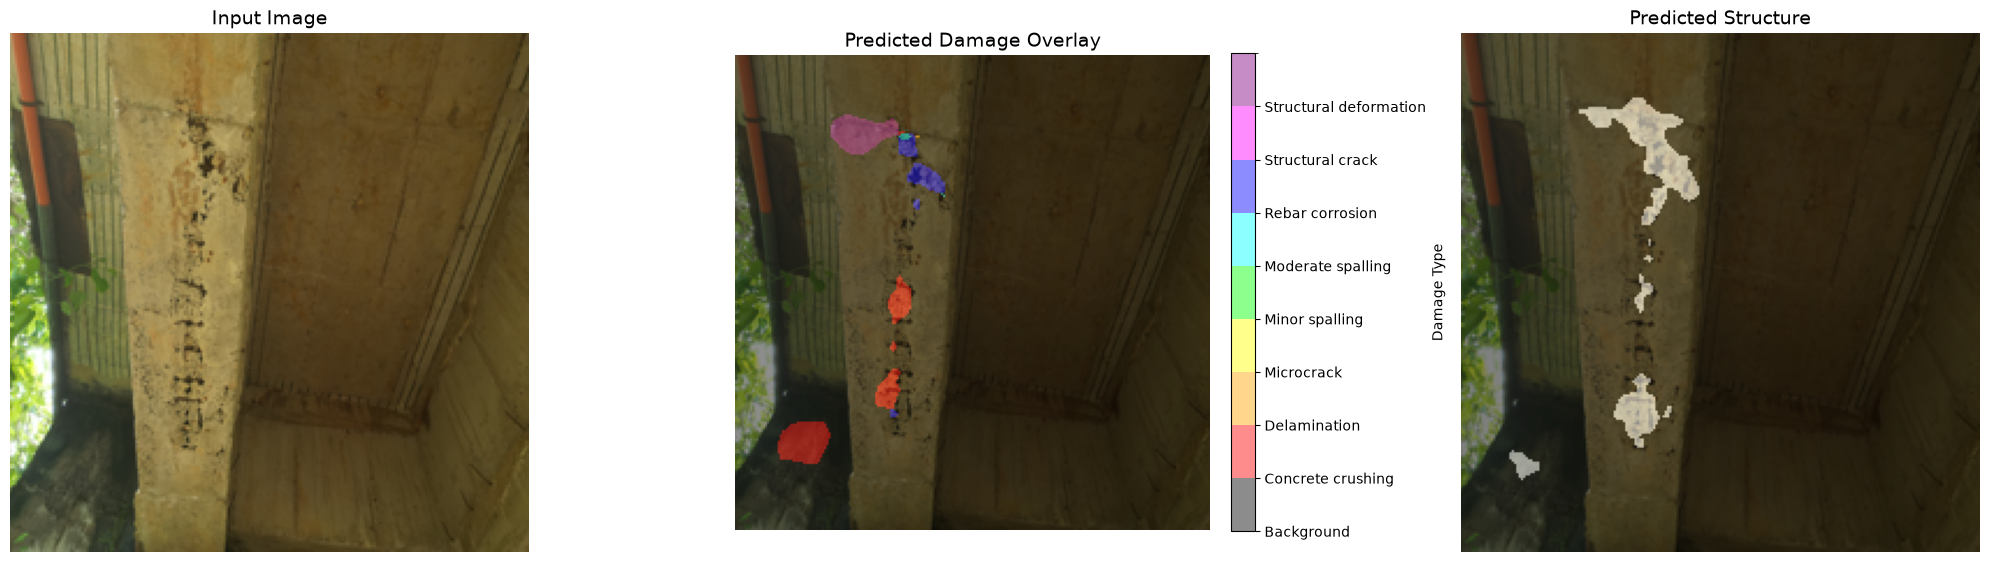

In [38]:
plot_prediction(
    model,
    "/storage/jothi/Sudhanshu/L_gate_data/DJI_0853.jpg" \
    "",
    dataset,
    device
)

In [36]:
torch.save({
    "epoch": epoch,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
}, "checkpoint.pth")

In [37]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(
    f"Total parameters: {total_params/1e6:.2f}M"
)

print(
    f"Trainable parameters: {trainable_params/1e6:.2f}M"
)

Total parameters: 28.66M
Trainable parameters: 0.37M
